# Coloration de graphes — validité statistique d'une comparaison de stratégies

**Notebook compagnon de [`App-02-GraphColoring-Python.ipynb`](App-02-GraphColoring-Python.ipynb).**

Le notebook `App-02` compare trois stratégies de coloration — **glouton** séquentiel, **DSATUR** (degré de saturation) et **CP-SAT** (programmation par contraintes via OR-Tools) — sur un graphe aléatoire et conclut, par exemple, que « CP-SAT utilise 18 couleurs, DSATUR 19, le glouton 22 ». Mais cette conclusion repose sur **une seule instance**. Or le graphe tiré au hasard n'est qu'**un tirage** parmi une infinité de graphes de même taille et même densité : un autre tirage pourrait rapprocher les stratégies, voire les inverser sur certaines métriques.

Ce notebook pose la question méthodologique qui manque à `App-02` : **quand peut-on affirmer qu'une stratégie est *significativement* meilleure qu'une autre**, plutôt que d'avoir observé un écart dû au hasard de l'échantillonnage des graphes ?

## Plan

1. **Le piège de l'instance unique** — pourquoi une comparaison ponctuelle n'est pas une preuve.
2. **Distribution *cross-instance*** — échantillonner $N$ graphes d'Erdős-Rényi $G(n,p)$ et regarder la distribution du nombre de couleurs de chaque stratégie.
3. **Intervalle de confiance bootstrap à 95 %** — encadrer l'écart moyen sans hypothèse de normalité.
4. **Test apparié par paires** (Wilcoxon signé) — l'écart est-il statistiquement significatif ? (+ correction de Bonferroni pour les comparaisons multiples).
5. **Taille d'effet *rank-bisérial apparié*** — significatif $\neq$ important.
6. **Effet de la densité** — le gap glouton/DSATUR dépend-il de $p$ ?

> **Famille conceptuelle.** Ce notebook est le troisième d'une veine « validité statistique d'une comparaison » : [`Sudoku-18b`](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb) étudie la variance du **temps** de solveurs déterministes ; `ML-04b` (série ML) étudie la variance des **métriques** d'un modèle en cross-validation. Ici, la stochasticité est d'une autre nature : elle vient de la **génération aléatoire des instances** (le graphe lui-même), pas du temps système ni de l'initialisation. Les stratégies sont déterministes, mais la *question posée* — « sur quels graphes cette stratégie gagne-t-elle ? » — est aléatoire.

**Pré-requis :** avoir parcouru `App-02-GraphColoring-Python` (définitions de coloration, nombre chromatique $\chi$, principe du glouton / DSATUR / CP-SAT).

**Navigation** : [Application GraphColoring en Python](App-02-GraphColoring-Python.ipynb) | [Application GraphColoring en C#](App-02-GraphColoring-CSharp.ipynb) | [Jumeau statistique en C#](App-02-GraphColoring-Statistical-Validity-CSharp.ipynb) | [Index de la partie](README.md) | [Index de la série](../README.md)

## 1. Mise en place — trois stratégies de coloration

Nous réimplémentons les trois stratégies de `App-02` sous une forme minimale et commentée, afin de pouvoir les lancer sur $N$ graphes sans dépendre d'artefacts extérieurs. La stack est la même que `App-02` : `networkx` (graphes), `ortools.sat.python.cp_model` (CP-SAT), plus `numpy` / `scipy` / `matplotlib` pour la statistique et les figures.

> **Reproductibilité.** Les graines sont fixées. CP-SAT emploie un budget de temps déterministe, un worker et une graine fixe ; ce budget ne représente pas des secondes murales. Les versions des bibliothèques, les générateurs et les plateformes peuvent modifier les résultats.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy import stats
from ortools.sat.python import cp_model

SEED = 42
rng = np.random.default_rng(SEED)

# Style des figures
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def greedy_color(G, order=None):
    """Glouton séquentiel : couleur la plus basse non utilisée par les voisins.
    `order` = ordre des sommets (par défaut, l'ordre networkx)."""
    nodes = list(G.nodes()) if order is None else order
    color = {}
    for u in nodes:
        used = {color[v] for v in G[u] if v in color}
        c = 0
        while c in used:
            c += 1
        color[u] = c
    return max(color.values()) + 1 if color else 0


def dsatur_color(G):
    """DSATUR : à chaque pas, colorer le sommet de saturation maximale
    (nombre de couleurs distinctes parmi les voisins déjà colorés),
    départage les égalités par le degré décroissant."""
    color = {}
    saturation = {u: 0 for u in G}
    degree = dict(G.degree())
    while len(color) < len(G):
        u = max((v for v in G if v not in color),
                key=lambda v: (saturation[v], degree[v]))
        used = {color[v] for v in G[u] if v in color}
        c = 0
        while c in used:
            c += 1
        color[u] = c
        for w in G[u]:
            if w not in color:
                saturation[w] = len({color[v] for v in G[w] if v in color})
    return max(color.values()) + 1


def cpsat_color(G, time_limit=2.0):
    """Coloration par CP-SAT (OR-Tools), bornée supérieurement par le glouton.
    Renvoie (k, statut) : k = nombre de couleurs de la meilleure solution
    trouvée dans le budget de temps ; statut = "OPTIMAL" si k est le nombre
    chromatique chi prouvé (optimalité démontrée par le solveur), "FEASIBLE"
    si k n'est qu'une borne supérieure de chi (solution valide trouvée sans
    preuve d'optimalité dans le budget de temps).

    Le budget est un temps déterministe, avec un seul worker et une graine
    fixée ; il ne représente pas des secondes murales. En cas de statut
    UNKNOWN ou MODEL_INVALID, aucune mesure CP-SAT n’est renvoyée."""
    n = len(G)
    if n == 0:
        return 0, "OPTIMAL"  # graphe vide : chi = 0, trivialement optimal
    nodes = list(G.nodes())
    idx = {u: i for i, u in enumerate(nodes)}
    ub = greedy_color(G)  # borne supérieure = résultat glouton
    model = cp_model.CpModel()
    x = {(v, c): model.NewBoolVar(f"x_{v}_{c}")
         for v in range(n) for c in range(ub)}
    for v in range(n):
        model.Add(sum(x[(v, c)] for c in range(ub)) == 1)
    for u, w in G.edges():
        iu, iw = idx[u], idx[w]
        for c in range(ub):
            model.Add(x[(iu, c)] + x[(iw, c)] <= 1)
    used = []
    for c in range(ub):
        uc = model.NewBoolVar(f"used_{c}")
        model.AddMaxEquality(uc, [x[(v, c)] for v in range(n)])
        used.append(uc)
    model.Minimize(sum(used))
    solver = cp_model.CpSolver()
    solver.parameters.max_deterministic_time = time_limit
    solver.parameters.num_search_workers = 1
    solver.parameters.random_seed = SEED
    status = solver.Solve(model)
    if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return int(round(solver.ObjectiveValue())), solver.StatusName(status)
    return None, solver.StatusName(status)  # aucune mesure CP-SAT sans solution


print("Stratégies chargées : glouton, DSATUR, CP-SAT.")

Stratégies chargées : glouton, DSATUR, CP-SAT.


## 2. Le piège de l'instance unique

Comparons les trois stratégies sur **un seul** graphe $G(50, 0{,}4)$, comme le ferait une conclusion ponctuelle :

In [2]:
G_one = nx.gnp_random_graph(50, 0.4, seed=42)
g1, d1 = greedy_color(G_one), dsatur_color(G_one)
c1, statut_c1 = cpsat_color(G_one)
print(f"Une instance G(50, 0.4) : glouton={g1}, DSATUR={d1}, CP-SAT={c1} (statut : {statut_c1})")
print(f"Écart glouton→CP-SAT : {g1 - c1} couleurs." if c1 is not None else f"Pas de solution CP-SAT ; borne gloutonne séparée : {g1} couleurs.")

Une instance G(50, 0.4) : glouton=12, DSATUR=9, CP-SAT=8 (statut : FEASIBLE)
Écart glouton→CP-SAT : 4 couleurs.


Une instance illustre seulement un tirage. Un statut `FEASIBLE` indique une borne supérieure valide, tandis que `OPTIMAL` prouve le nombre chromatique pour le modèle. Sans solution, la borne gloutonne est rapportée séparément. Sur cette instance, le glouton utilise 12 couleurs, DSATUR 9 et CP-SAT 8 avec le statut FEASIBLE.

## 3. Distribution *cross-instance* — échantillonner $N$ graphes

Nous générons $N = 20$ graphes indépendants $G(50, 0{,}4)$ et reportons le nombre de couleurs de chaque stratégie. La distribution empirique (et non la seule moyenne) révèle la variabilité due à l'échantillonnage des graphes.

In [3]:
N_INSTANCES = 20
N_NODES = 50
P_DENSE = 0.4

# Graines déterministes dérivées du RNG maître (reproductible)
seeds = [int(s) for s in rng.integers(1, 10**9, size=N_INSTANCES)]
graphs = [nx.gnp_random_graph(N_NODES, P_DENSE, seed=s) for s in seeds]

greedy_res = np.array([greedy_color(G) for G in graphs])
dsatur_res = np.array([dsatur_color(G) for G in graphs])
cpsat_solutions = [cpsat_color(G, time_limit=2.0) for G in graphs]
cpsat_mask = np.array([k is not None for k, _ in cpsat_solutions])
cpsat_res = np.array([k for k, _ in cpsat_solutions if k is not None])
if not len(cpsat_res):
    raise RuntimeError("Aucune solution CP-SAT : aucune statistique comparative disponible")
n_optimal = sum(1 for _, s in cpsat_solutions if s == "OPTIMAL")
n_feasible = sum(1 for _, s in cpsat_solutions if s == "FEASIBLE")

print(f"Sur N={N_INSTANCES} graphes G({N_NODES}, {P_DENSE}) :")
print(f"  glouton : moyenne={greedy_res.mean():.2f}  médiane={np.median(greedy_res):.0f}  écart-type={greedy_res.std():.2f}  min/max={greedy_res.min()}/{greedy_res.max()}")
print(f"  DSATUR  : moyenne={dsatur_res.mean():.2f}  médiane={np.median(dsatur_res):.0f}  écart-type={dsatur_res.std():.2f}  min/max={dsatur_res.min()}/{dsatur_res.max()}")
print(f"  CP-SAT  : moyenne={cpsat_res.mean():.2f}  médiane={np.median(cpsat_res):.0f}  écart-type={cpsat_res.std():.2f}  min/max={cpsat_res.min()}/{cpsat_res.max()}")
print(f"  statuts CP-SAT : {n_optimal} OPTIMAL / {n_feasible} FEASIBLE / {N_INSTANCES - len(cpsat_res)} sans solution (exclus)")
for i, (k, status) in enumerate(cpsat_solutions):
    if k is None:
        print(f"  graphe {i} : {status}, borne gloutonne séparée = {greedy_res[i]}")

Sur N=20 graphes G(50, 0.4) :
  glouton : moyenne=10.95  médiane=11  écart-type=0.86  min/max=10/13
  DSATUR  : moyenne=9.40  médiane=9  écart-type=0.58  min/max=9/11
  CP-SAT  : moyenne=8.00  médiane=8  écart-type=0.32  min/max=7/9
  statuts CP-SAT : 1 OPTIMAL / 19 FEASIBLE / 0 sans solution (exclus)


Les résumés montrent la variabilité entre graphes. Les statuts distinguent les optima prouvés des colorations faisables ; les résolutions sans solution sont exclues des mesures CP-SAT. Dans cette exécution, les moyennes sont respectivement 10,95, 9,40 et 8,00 couleurs ; CP-SAT prouve un optimum sur une instance et trouve une solution faisable sur 19.

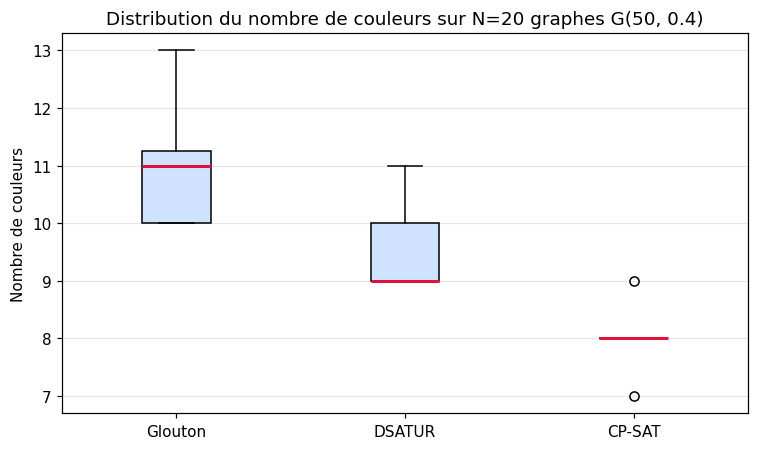

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
data = [greedy_res, dsatur_res, cpsat_res]
labels = ["Glouton", "DSATUR", "CP-SAT"]
ax.boxplot(data, tick_labels=labels, patch_artist=True,
           boxprops=dict(facecolor="#cfe2ff"), medianprops=dict(color="crimson", linewidth=2))
ax.set_ylabel("Nombre de couleurs")
ax.set_title(f"Distribution du nombre de couleurs sur N={N_INSTANCES} graphes G({N_NODES}, {P_DENSE})")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Les boîtes comparent les distributions empiriques. Une séparation visuelle ne remplace pas un test apparié.

## 4. Intervalle de confiance bootstrap à 95 %

La moyenne empirique $\bar{x}$ n'est qu'une estimation de la moyenne « vraie » $\mu$ sur la population (infinie) des graphes $G(50, 0{,}4)$. Le **bootstrap non paramétrique** estime l'incertitude sur $\bar{x}$ en rééchantillonnant avec remise les $N$ observations, sans supposer de loi (Gaussienne ou autre) sur les données.

On tire $B$ échantillons *bootstrap* (de même taille $N$, avec remise), on calcule la moyenne de chacun, et on prend les quantiles à 2,5 % et 97,5 % comme borne de l'IC à 95 %.

In [5]:
def bootstrap_ic(echantillon, B=2000, confiance=0.95, seed=SEED):
    """IC bootstrap non paramétrique sur la moyenne."""
    rng_b = np.random.default_rng(seed)
    n = len(echantillon)
    boot_means = np.array([
        np.mean(rng_b.choice(echantillon, size=n, replace=True))
        for _ in range(B)
    ])
    alpha = (1 - confiance) / 2
    lo = np.percentile(boot_means, 100 * alpha)
    hi = np.percentile(boot_means, 100 * (1 - alpha))
    return float(lo), float(hi)


print(f"IC 95% bootstrap (B=2000) sur le nombre de couleurs moyen :")
for nom, res in [("Glouton", greedy_res), ("DSATUR", dsatur_res), ("CP-SAT", cpsat_res)]:
    lo, hi = bootstrap_ic(res)
    print(f"  {nom:8} : {res.mean():5.2f}  IC95% = [{lo:.2f}, {hi:.2f}]  (largeur {hi-lo:.2f})")

IC 95% bootstrap (B=2000) sur le nombre de couleurs moyen :
  Glouton  : 10.95  IC95% = [10.55, 11.35]  (largeur 0.80)
  DSATUR   :  9.40  IC95% = [9.15, 9.70]  (largeur 0.55)
  CP-SAT   :  8.00  IC95% = [7.85, 8.15]  (largeur 0.30)


Les intervalles bootstrap décrivent l’incertitude sur chaque moyenne. Pour comparer les stratégies, le test suivant utilise les différences appariées sur les mêmes graphes. Les intervalles observés vont de [10,55 ; 11,35] pour le glouton à [7,85 ; 8,15] pour CP-SAT.

## 5. Test apparié par paires (Wilcoxon signé) + correction de Bonferroni

« Les IC sont disjoints » suggère une différence, mais ne répond pas formellement à la question de la *signification*. Le protocole est **apparié** : à chaque indice $i$, les trois valeurs (glouton, DSATUR, CP-SAT) proviennent du **même** graphe $G_i$. Le test adapté est donc le **test de Wilcoxon sur rangs signés** (non paramétrique, apparié) : sur les différences $d_i = A(G_i) - B(G_i)$, il teste $H_0$ : « les $d_i$ sont symétriquement répartis autour de zéro » contre $H_1$ : « la stratégie A utilise strictement plus de couleurs que B ». Un test pour échantillons **indépendants** (Mann-Whitney) ne serait pas adapté ici : en ignorant l'appariement par graphe, il fausserait la force de la preuve.

**Convention pour les différences nulles** (`zero_method="wilcox"` de SciPy) : les ex aequo ($d_i = 0$) sont exclus avant le classement des rangs. Cette même convention servira de base à la taille d'effet de la section 6 — test et effet sont ainsi calculés sur les mêmes différences non nulles.

Comme nous faisons **trois** comparaisons par paires (glouton/DSATUR, DSATUR/CP-SAT, glouton/CP-SAT), le risque de faux positif gonfle. La **correction de Bonferroni** divise le seuil $\alpha$ par le nombre de comparaisons ($\alpha/3$) pour contrôler le risque global — elle corrige la multiplicité des tests ; elle ne remplace pas le choix d'un test adapté au protocole.

In [6]:
paires = [
    ("Glouton", greedy_res, "DSATUR", dsatur_res),
    ("DSATUR", dsatur_res[cpsat_mask], "CP-SAT", cpsat_res),
    ("Glouton", greedy_res[cpsat_mask], "CP-SAT", cpsat_res),
]
m = len(paires)  # nombre de comparaisons
alpha_brut = 0.05
alpha_bonf = alpha_brut / m

print(f"3 comparaisons appariées par paires — seuil alpha = {alpha_brut}, corrigé Bonferroni = {alpha_bonf:.4f}\n")
print(f"{'Comparaison':<20} {'W':>8} {'p (brut)':>14} {'p < bonf?':>11}")
for (na, va, nb, vb) in paires:
    W, pval = stats.wilcoxon(va, vb, alternative="greater", zero_method="wilcox")
    verdict = "OUI" if pval < alpha_bonf else "non"
    print(f"{na+' > '+nb:<20} {W:>8.0f} {pval:>14.2e} {verdict:>11}")

# Le meme contraste en test NON apparie (Mann-Whitney) : la lecture de la
# section 5 explique pourquoi ces p-valeurs, plus petites, suraffirment.
print()
print(f"{'Comparaison':<20} {'p (Mann-Whitney)':>18}")
for (na, va, nb, vb) in paires:
    U, p_mw = stats.mannwhitneyu(va, vb, alternative="greater")
    print(f"{na+' > '+nb:<20} {p_mw:>18.2e}")

3 comparaisons appariées par paires — seuil alpha = 0.05, corrigé Bonferroni = 0.0167

Comparaison                 W       p (brut)   p < bonf?
Glouton > DSATUR          171       7.40e-05         OUI
DSATUR > CP-SAT           210       2.41e-05         OUI
Glouton > CP-SAT          210       3.28e-05         OUI

Comparaison            p (Mann-Whitney)
Glouton > DSATUR               1.15e-06
DSATUR > CP-SAT                9.58e-09
Glouton > CP-SAT               5.85e-09


Comparez chaque p-valeur appariée au seuil corrigé : le résultat concerne la distribution étudiée, sous les hypothèses du test. Le test indépendant omet l’appariement ; ses p-valeurs ne sont pas directement interchangeables avec celles du protocole apparié. Les p-valeurs appariées mesurées sont 7,40×10⁻⁵, 2,41×10⁻⁵ et 3,28×10⁻⁵, toutes sous le seuil 0,0167.

## 6. Taille d'effet *rank-bisérial apparié* — significatif $\neq$ important

Un $p$-value minuscule avec $N = 20$ peut simplement traduire « l'effet existe et $N$ suffit à le détecter », sans dire s'il est **grand**. La **taille d'effet rank-bisérial appariée** $r$ quantifie la magnitude, indépendamment de $N$, en restant sur les différences non nulles $d_i = A(G_i) - B(G_i)$ (convention de la section 5) :

$$r = \frac{R_+ - R_-}{R_+ + R_-} \in [-1, +1]$$

où $R_+$ (respectivement $R_-$) est la somme des rangs de $|d_i|$ — rangs calculés sur l'ensemble des différences non nulles — pour les $d_i > 0$ (respectivement $d_i < 0$). Ici $r = +1$ signifie « A utilise plus de couleurs que B sur toutes les instances non ex aequo », $r = 0$ « équilibre parfait des rangs », $r = -1$ « B utilise plus de couleurs que A partout ». C'est l'équivalent non paramétrique du « combien ça compte, pas seulement est-ce que ça existe ».

In [7]:
def rank_biserial_apparie(va, vb):
    """Rank-bisérial apparié : (R+ - R-)/(R+ + R-) sur les différences non
    nulles (convention zero_method='wilcox', cohérente avec la section 5)."""
    d = np.asarray(va) - np.asarray(vb)
    d = d[d != 0]
    if len(d) == 0:
        return 0.0
    rangs = stats.rankdata(np.abs(d))
    r_plus = rangs[d > 0].sum()
    r_moins = rangs[d < 0].sum()
    return float((r_plus - r_moins) / (r_plus + r_moins))


print(f"{'Comparaison':<20} {'r':>6}  bilan par paire (effectifs affichés)  [interpretation]")
for (na, va, nb, vb) in paires:
    r = rank_biserial_apparie(va, vb)
    interp = ("quasi-systématique" if r > 0.9 else
              "marquée" if r > 0.5 else
              "modérée" if r > 0.3 else "faible")
    d = np.asarray(va) - np.asarray(vb)   # d > 0 : nb l'emporte (moins de couleurs)
    vict = int((d > 0).sum())
    egal = int((d == 0).sum())
    defa = int((d < 0).sum())
    print(f"{na+' > '+nb:<20} {r:>6.3f}  {nb} gagne {vict}/{len(d)}, egalites {egal}, defaites {defa}  [{interp}]")

Comparaison               r  bilan par paire (effectifs affichés)  [interpretation]
Glouton > DSATUR      1.000  DSATUR gagne 18/20, egalites 2, defaites 0  [quasi-systématique]
DSATUR > CP-SAT       1.000  CP-SAT gagne 20/20, egalites 0, defaites 0  [quasi-systématique]
Glouton > CP-SAT      1.000  CP-SAT gagne 20/20, egalites 0, defaites 0  [quasi-systématique]


Le coefficient résume les rangs des différences non nulles, pas leur amplitude en nombre de couleurs. Les victoires, égalités et défaites complètent sa lecture ; les résultats CP-SAT faisables ne sont pas nécessairement des optima prouvés. Les trois coefficients valent 1,000 ; DSATUR gagne 18 fois face au glouton et égalise deux fois.

Dans les deux contrastes CP-SAT, les vingt solutions trouvées gagnent face aux stratégies comparées sur ce banc. Cela compare des colorations faisables, avec un seul optimum prouvé ; ni le coefficient maximal ni vingt victoires ne donnent un théorème sur tous les graphes.

**Choix des instances.** Une construction de Mycielski a un grand nombre chromatique sans triangle, mais cela ne garantit pas un écart entre heuristiques : l'ordre des sommets importe pour le glouton. Le banc dense d'Erdős–Rényi sert ici à mesurer un écart entre stratégies sur des instances effectivement générées ; aucune mauvaise performance sur toutes les constructions de Mycielski n'est supposée.


## 7. Effet de la densité — le gap dépend-il de $p$ ?

La conclusion précédente vaut pour $p = 0{,}4$. Le gap glouton/DSATUR est-il sensible à la densité du graphe ? Balayons $p \in [0{,}1, 0{,}7]$ (CP-SAT est délibérément omis du balayage : il est trop coûteux pour $7 \times N_{\text{sweep}}$ résolutions supplémentaires ; le cas principal ci-dessus a déjà montré qu'il ferme encore le gap à $p = 0{,}4$).

Sweep densité — écart glouton - DSATUR (N=15 graphes par p) :
    p | gap moyen | DSATUR gagne | égalités
 0.10 |     1.067 | 13/15        | 2
 0.20 |     1.533 | 15/15        | 0
 0.30 |     1.533 | 14/15        | 1
 0.40 |     1.533 | 14/15        | 1
 0.50 |     1.933 | 14/15        | 1
 0.60 |     1.800 | 14/15        | 1
 0.70 |     2.800 | 15/15        | 0


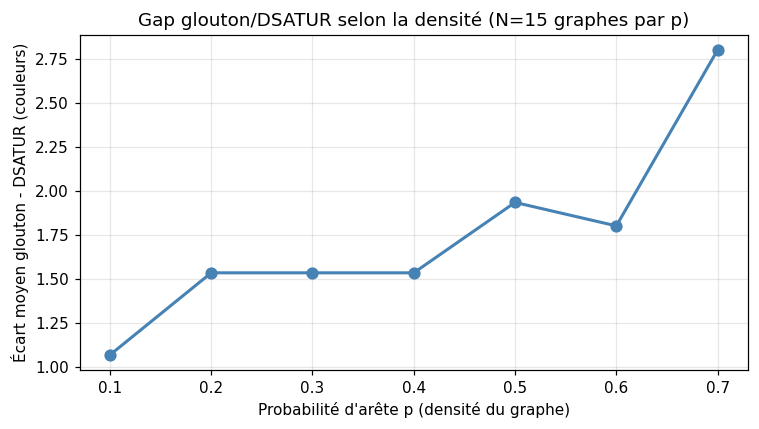

In [8]:
SWEEP_PS = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
N_SWEEP = 15

gap_mean = []      # écart moyen glouton - DSATUR selon p
wins_dsatur = []   # instances où DSATUR fait strictement mieux
egalites = []      # instances où les deux stratégies coïncident
for p in SWEEP_PS:
    sub_seeds = [int(s) for s in rng.integers(1, 10**9, size=N_SWEEP)]
    gaps = []
    for s in sub_seeds:
        G = nx.gnp_random_graph(N_NODES, p, seed=s)
        gaps.append(greedy_color(G) - dsatur_color(G))
    gap_mean.append(np.mean(gaps))
    wins_dsatur.append(sum(1 for d in gaps if d > 0))
    egalites.append(sum(1 for d in gaps if d == 0))

print("Sweep densité — écart glouton - DSATUR (N=15 graphes par p) :")
print(f"{'p':>5} | {'gap moyen':>9} | DSATUR gagne | égalités")
for p, g, w, e in zip(SWEEP_PS, gap_mean, wins_dsatur, egalites):
    print(f"{p:5.2f} | {g:9.3f} | {w:2d}/{N_SWEEP}        | {e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(SWEEP_PS, gap_mean, "o-", color="steelblue", linewidth=2, markersize=7)
ax.set_xlabel("Probabilité d'arête p (densité du graphe)")
ax.set_ylabel("Écart moyen glouton - DSATUR (couleurs)")
ax.set_title(f"Gap glouton/DSATUR selon la densité (N={N_SWEEP} graphes par p)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Le tableau et la courbe montrent comment le gap moyen varie avec la densité sur les échantillons tirés. Les fluctuations entre deux valeurs voisines ne garantissent pas une croissance monotone. Par exemple, le gap moyen passe de 1,067 à p=0,1 à 1,933 à p=0,5 puis 1,800 à p=0,6.

## 8. Synthèse — relire `App-02` à la lumière des intervalles

La comparaison ponctuelle décrit une instance. Les intervalles bootstrap, les tests appariés avec correction de Bonferroni et les rangs bisériaux décrivent les 20 graphes échantillonnés et leurs différences. Les mesures CP-SAT portent uniquement sur les solutions trouvées ; une borne gloutonne de repli n'est pas attribuée au solveur. Le budget de 2 unités est déterministe et ne correspond pas à deux secondes murales. Le balayage explore la densité sans démontrer de monotonie générale.

| Question | Conclusion pour ce banc fini | Limite |
|---|---|---|
| DSATUR utilise-t-il moins de couleurs que le glouton ? | Le contraste apparié est sous le seuil corrigé ; 18 victoires et deux égalités | Dépend des graphes et de l'ordre des sommets |
| CP-SAT utilise-t-il moins de couleurs que DSATUR ? | Le contraste apparié est sous le seuil corrigé | Les valeurs faisables sont des bornes supérieures, sauf preuve OPTIMAL |
| L'écart croît-il avec la densité ? | Le balayage mesure une dépendance sur les échantillons tirés | La croissance n'est pas monotone sur toutes les densités voisines |

La même discipline apparaît dans [Sudoku-18b](../../Sudoku/Sudoku-18b-Statistical-Comparison-Python.ipynb) pour les temps des solveurs et dans ML-04b pour les métriques de modèles : distinguer protocole, variabilité mesurée et portée de l'inférence. Un test apparié n'est pas interchangeable avec un test indépendant choisi parce que sa p-valeur semble plus petite.


## Exercices

Les trois exercices suivants sont à compléter. L'objectif est d'expérimenter vous-même la méthodologie sur des variantes du problème.

### Exercice 1 — Une quatrième stratégie : Welsh-Powell

Implémentez la coloration **Welsh-Powell** : comme le glouton séquentiel, mais en traitant les sommets **par degré décroissant**. Ajoutez-la au benchmark ci-dessus et testez (Wilcoxon signé apparié + taille d'effet, en réutilisant la convention des différences nulles de la section 5) si elle est significativement meilleure que le glouton séquentiel *par ordre networkx* sur les mêmes $N$ graphes.

*Indice :* `order = sorted(G.nodes(), key=lambda v: G.degree(v), reverse=True)` puis passez `order` à `greedy_color`.

In [9]:
# Exercice 1 — à compléter
# 1. Définissez welsh_powell_color(G) en réutilisant greedy_color(G, order=...).
# 2. Calculez son résultat sur les N=20 graphes `graphs` déjà générés.
# 3. Comparez-la au glouton séquentiel (greedy_res) par Wilcoxon signé apparié
#    (stats.wilcoxon, zero_method="wilcox") + rank-bisérial apparié.
# 4. Affichez l'IC 95% bootstrap de la moyenne.

def welsh_powell_color(G):
    # TODO étudiant : trier les sommets par degré décroissant, appeler greedy_color
    result = None  # TODO
    return result

# TODO : benchmark + tests statistiques sur `graphs`
print("Exercice à compléter")

Exercice à compléter


### Exercice 2 — Vers des graphes encore plus denses

Reproduisez le balayage de densité de la section 7, mais en **rajoutant CP-SAT** sur un sous-ensemble plus petit (par exemple $N_{\text{CP-SAT}} = 5$ instances par valeur de $p$). Le gap DSATUR/CP-SAT s'annule-t-il à forte densité ($p \geq 0{,}6$) ?

*Indice :* attention au temps de calcul — augmentez `time_limit` de CP-SAT si certaines instances n'atteignent pas l'optimum prouvé.

In [10]:
# Exercice 2 — à compléter
# Reproduisez le sweep densité avec CP-SAT sur N_CP_SAT = 5 instances par p.
# Pour chaque p, comparez DSATUR vs CP-SAT (gap moyen) et observez la tendance.

print("Exercice à compléter")

Exercice à compléter


### Exercice 3 — Tail-effect : médiane vs moyenne

Pour CP-SAT (le plus régulier), comparez la **moyenne** et la **médiane** du nombre de couleurs sur les $N = 20$ instances. Si elles diffèrent, que dit cela de la forme de la distribution (symétrique ou asymétrique) ? Calculez un IC bootstrap sur la *médiane* et comparez sa largeur à celui de la moyenne.

*Indice :* une différence entre moyenne et médiane peut suggérer une asymétrie ; elle ne suffit pas à en démontrer la forme.

In [11]:
# Exercice 3 — à compléter
# 1. Comparez moyenne et médiane de cpsat_res.
# 2. Adaptez bootstrap_ic pour renvoyer l'IC sur la médiane (remplacez np.mean par np.median).
# 3. Comparez les largeurs d'IC moyenne vs médiane.

print("Exercice à compléter")

Exercice à compléter
